# ZollerQu: long/short stock split (Qollab × IonQ hackathon)

This effort is supported by Qollab & IonQ.

Working notebook, built cell by cell. Local development only: the Qollab entry point will be a separate `main.py`, and the reusable code lives in the `stocks/` package next to this notebook.

## Run settings (change here, then Run All)

Two benchmark sizes. Each asset is one qubit.
- **Small**: the quick run. It finishes fast on any free Qollab simulator and is what judges will press Run on.
- **Large**: the full run on IonQ Forte 1 (noise model), up to its 29-qubit limit. It is slow in the shared queue, so we record the result and ship it.

`RUN_SIZES` lists the sizes the benchmark cells will run (later tasks). Add 16, 20 or 24 for a scaling table.
Above about 22 qubits two parts change: the exact optimum becomes the *best known* answer from classical solvers, and a noiseless simulation on a laptop is no longer possible (2^29 amplitudes). The IonQ run itself works up to 29.

In [1]:
QUBITS_SMALL = 12   # quick run (Qollab live demo)
QUBITS_LARGE = 29   # full run (IonQ Forte 1 noise model, maximum 29)
RUN_SIZES = [QUBITS_SMALL, QUBITS_LARGE]

for n in RUN_SIZES:
    if not 2 <= n <= 29:
        raise ValueError(f"size {n}: must be between 2 and 29 qubits (IonQ Forte 1 limit)")
print("benchmark sizes (qubits = assets):", RUN_SIZES)

benchmark sizes (qubits = assets): [12, 29]


## Task 1: Load and validate the OR-Library dataset

Source: J E Beasley, OR-Library, `indtrack1.txt` (index tracking problem 1, MIT licence). Downloaded once during development; nothing is downloaded at run time.

In [2]:
import hashlib
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "stocks").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from stocks import data, validate_data

print("repo root:", ROOT)

repo root: /Users/t/zollerqu-qollab


### 1.1 Source file as downloaded

In [3]:
raw = data.RAW_PATH
lines = raw.read_text().splitlines()
print("file:  ", raw.relative_to(ROOT), f"({raw.stat().st_size} bytes)")
print("sha256:", hashlib.sha256(raw.read_bytes()).hexdigest())
print("line 1:", repr(lines[0]))
print("line 2:", repr(lines[1]))
values_per_line = [len(line.split()) for line in lines[1:]]
print("lines after header:", len(values_per_line),
      "| with 4 values:", values_per_line.count(4),
      "| with 3 values:", values_per_line.count(3),
      "| total values:", sum(values_per_line))

file:   data/raw/indtrack1.txt (116665 bytes)
sha256: 258b917e304e21c87ae481b9baba0aefe877b657fa63483255c23162a74aa629
line 1: ' 31 290 '
line 2: ' 8749.31759356 8713.53262793 9001.60515134 8903.30299873 '
lines after header: 2336 | with 4 values: 2304 | with 3 values: 32 | total values: 9312


### 1.2 Parse and validate

`parse_orlib` accepts a layout only if the price count matches it **and** every series starts on a new line. It also checks that the first index price is near 8749 and that all prices are finite and positive. Any problem raises `DataFormatError`; nothing is dropped or filled in.

In [4]:
market, report = data.parse_orlib(raw)
print(report)
print("index:", market.index.shape, "| stocks:", market.prices.shape, "| names:", market.names[0], "...", market.names[-1])
print("first index price:", float(market.index[0]))
print(f"index range {market.index.min():.2f} .. {market.index.max():.2f} | "
      f"stock range {market.prices.min():.4f} .. {market.prices.max():.4f}")

ParseReport(header=(31, 290), n_values=9312, layout='(N+1)*(T+1)', n_series=32, observations=291)
index: (291,) | stocks: (291, 31) | names: s01 ... s31
first index price: 8749.31759356
index range 8713.53 .. 29550.18 | stock range 1.7928 .. 484.5881


### 1.3 Normalised CSV `data/hangseng_weekly.csv`

One row per observation: `week,index,s01,...,s31`. The source has no dates, so `week` is the observation number 0..290 in source order.

In [5]:
data.write_csv(market, data.CSV_PATH)
reloaded = data.load_csv(data.CSV_PATH)
same = (reloaded.names == market.names
        and (reloaded.index == market.index).all()
        and (reloaded.prices == market.prices).all())
print("reloaded identical to the parsed source:", same)
for line in data.CSV_PATH.read_text().splitlines()[:3]:
    print(line[:100] + " ...")

reloaded identical to the parsed source: True
week,index,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21,s22,s ...
0,8749.31759356,9.33675195,14.37788798,7.36644878,29.46579511,5.55589992,8.55573087,16.41919306,9.95 ...
1,8713.53262793,9.86926631,14.18263271,7.40194974,27.33573763,5.44939705,8.50247943,16.41919306,9.28 ...


### 1.4 Licence notice

In [6]:
ok, message = validate_data.check_licence()
print(message)
print()
print("\n".join(data.LICENSE_PATH.read_text().splitlines()[:10]))

verified (data/LICENSE_ORLIB.txt holds the full MIT notice, copied verbatim from OR-Library legal.html)

OR-Library licence notice for data/raw/indtrack1.txt and data/hangseng_weekly.csv

Data:    indtrack1.txt (index tracking test problem 1), OR-Library, J E Beasley
         https://people.brunel.ac.uk/~mastjjb/jeb/orlib/files/indtrack1.txt
Notice:  copied verbatim from https://people.brunel.ac.uk/~mastjjb/jeb/orlib/legal.html
         on 2026-10-10. Only the HTML markup was removed; the wording, line breaks and
         the original "(J E Beasley}" bracket are unchanged.
Changes: data/hangseng_weekly.csv holds the same prices rearranged into columns by
         stocks/data.py (team ZollerQu). No values were added, removed or altered.


### 1.5 Task 1 report (also runs the 23 unit tests)

Same output as `python -m stocks.validate_data` from the repo root.

In [7]:
exit_code = validate_data.main()

[TASK 1] OR-Library dataset validation
- Source: original OR-Library file data/raw/indtrack1.txt (sha256 258b917e304e21c8...)
- Header: 31 290
- Layout: (N+1)*(T+1) = 32 series x 291 = 9312 prices, each series starting on a new line
- Stock series: 31
- Index series: 1
- Price observations per series: 291 (index: 291)
- First index price: 8749.31759356
- Invalid or missing prices: 0 (counted in the written CSV)
- CSV output: data/hangseng_weekly.csv (291 rows x 33 columns, reload identical to source: yes)
- Licence notice: verified (data/LICENSE_ORLIB.txt holds the full MIT notice, copied verbatim from OR-Library legal.html)
- Tests: 23 passed, 0 failed
RESULT: PASS


### 1.6 What the data contains

Price summary for all 31 stocks and the index, then a sample of the weekly prices. The source file has no company names or dates: stocks are labelled `s01`..`s31` in file order and `week` is the observation number. Prices are in the units of the source file.

In [8]:
import pandas as pd

pd.set_option("display.float_format", "{:,.2f}".format)
df = pd.read_csv(data.CSV_PATH).set_index("week")
series = ["index"] + market.names
first, last = df[series].iloc[0], df[series].iloc[-1]
summary = pd.DataFrame({
    "first price (week 0)": first,
    "last price (week 290)": last,
    "lowest": df[series].min(),
    "highest": df[series].max(),
    "change week 0 to 290 (%)": (last / first - 1) * 100,
})
summary.index.name = "series"
print(f"{len(market.names)} stocks + 1 index, {len(df)} weekly prices each (weeks {df.index[0]} to {df.index[-1]})")
summary

31 stocks + 1 index, 291 weekly prices each (weeks 0 to 290)


,first price (week 0),last price (week 290),lowest,highest,change week 0 to 290 (%)
series,,,,,
index,"8,749.32","25,532.52","8,713.53","29,550.18",191.82
s01,9.34,17.13,8.73,27.34,83.46
s02,14.38,48.28,14.18,57.33,235.80
s03,7.37,8.25,7.01,17.93,12.05
s04,29.47,123.81,24.85,143.34,320.18
s05,5.56,15.98,5.33,16.69,187.54
s06,8.56,26.98,8.50,29.64,215.35
s07,16.42,41.36,15.80,55.47,151.89
s08,9.96,14.56,8.43,23.79,46.17


In [9]:
sample = ["index", "s01", "s02", "s03", "s04", "s05", "s06"]
print("Sample: first 5 and last 5 weeks, index + stocks s01 to s06")
pd.concat([df[sample].head(5), df[sample].tail(5)])

Sample: first 5 and last 5 weeks, index + stocks s01 to s06


,index,s01,s02,s03,s04,s05,s06
week,,,,,,,
0,"8,749.32",9.34,14.38,7.37,29.47,5.56,8.56
1,"8,713.53",9.87,14.18,7.40,27.34,5.45,8.50
2,"9,001.61",9.96,14.59,7.77,28.76,5.80,8.73
3,"8,903.30",9.16,15.74,7.63,28.76,5.50,8.86
4,"8,888.69",9.25,16.29,7.49,27.87,5.50,9.21
286,"27,388.55",17.57,53.78,8.47,135.79,15.89,29.11
287,"25,090.75",16.86,49.08,8.22,114.49,14.56,25.56
288,"25,851.00",17.04,48.28,7.77,126.03,15.53,27.34
289,"25,685.76",17.04,48.81,8.29,126.03,15.00,27.42


### 1.7 Stock names: not available in the data

The company names are **not in the dataset, and no public source we found lists them**. The FRAPO R package documentation for this data (INDTRACK1) says: *"The data was downloaded from DATASTREAM and has been anonymized"*, and describes it as weekly prices of the Hang Seng index and 31 of its constituents, March 1991 to September 1997. OR-Library gives no names either.

- `s01`..`s31` are simply the order of the stocks in the source file.
- We do **not** guess names from price patterns: a guess could not be verified and would undo the anonymisation.
- Consequence for the project: results describe the method on real 1990s Hong Kong stock prices, not named companies. Named stocks would need a different price dataset that we are licensed to ship.

### 1.8 Price paths of all 31 stocks and the index

Every series is rebased to 100 at week 0, so all paths start at the same point and can be compared. Log scale, so a doubling looks the same size everywhere. Grey: stocks; blue: the index; orange: the stock with the largest rise. The exact numbers are in the table in 1.6.

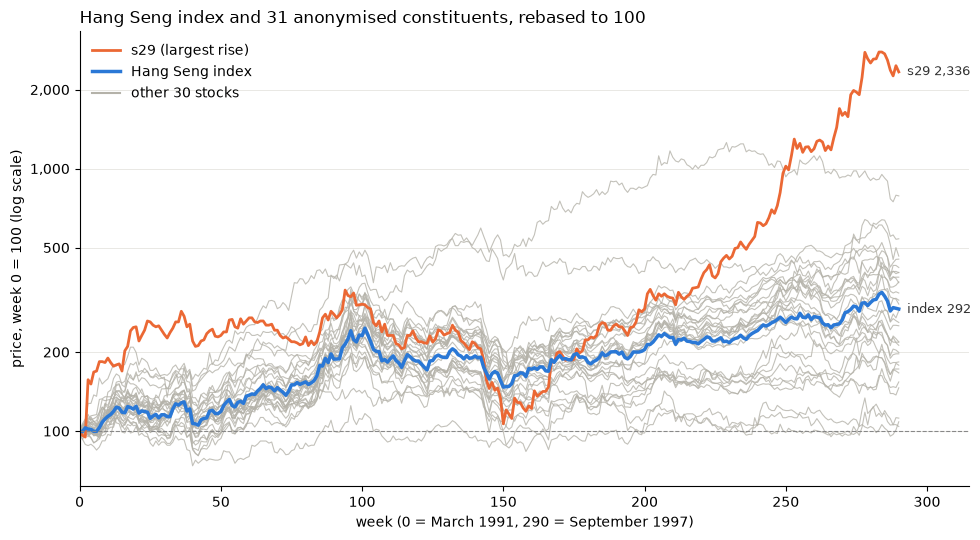

Text summary: the index ends at 292 (start = 100). 31 of 31 stocks end above 100; the median stock ends at 259; 14 stocks end above the index. Largest rise: s29 at 2,336; smallest: s14 at 104.


In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

rebased = df[series] / df[series].iloc[0] * 100
final = rebased.iloc[-1]
top = final[market.names].idxmax()

fig, ax = plt.subplots(figsize=(10, 5.5))
for name in market.names:
    if name != top:
        ax.plot(rebased.index, rebased[name], color="#b4b2a9", linewidth=0.8, alpha=0.8)
ax.plot(rebased.index, rebased[top], color="#eb6834", linewidth=2, label=f"{top} (largest rise)")
ax.plot(rebased.index, rebased["index"], color="#2a78d6", linewidth=2.5, label="Hang Seng index")
ax.plot([], [], color="#b4b2a9", linewidth=1.5, label="other 30 stocks")

ax.set_yscale("log")
ax.yaxis.set_major_locator(FixedLocator([50, 100, 200, 500, 1000, 2000]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_locator(FixedLocator([]))
for name, color in [(top, "#eb6834"), ("index", "#2a78d6")]:
    label = "index" if name == "index" else name
    ax.annotate(f"{label} {final[name]:,.0f}", (rebased.index[-1], final[name]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#333333")
ax.axhline(100, color="#888888", linewidth=0.8, linestyle="--")
ax.set_xlim(0, rebased.index[-1] + 25)
ax.set_xlabel("week (0 = March 1991, 290 = September 1997)")
ax.set_ylabel("price, week 0 = 100 (log scale)")
ax.set_title("Hang Seng index and 31 anonymised constituents, rebased to 100", loc="left")
ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

stocks_final = final[market.names]
print(f"Text summary: the index ends at {final['index']:.0f} (start = 100). "
      f"{(stocks_final > 100).sum()} of {len(stocks_final)} stocks end above 100; the median stock ends at "
      f"{stocks_final.median():.0f}; {(stocks_final > final['index']).sum()} stocks end above the index. "
      f"Largest rise: {stocks_final.idxmax()} at {stocks_final.max():,.0f}; smallest: "
      f"{stocks_final.idxmin()} at {stocks_final.min():.0f}.")

## Kaggle dataset: named US stocks and ETFs (first look)

Source: Boris Marjanovic, *Huge Stock Market Dataset*, Kaggle, licence **CC0 (public domain)**. Daily prices of US stocks and ETFs (exchange-traded funds), adjusted for dividends and splits, up to 10 Nov 2017. Downloaded 2026-10-10 to `data/raw/kaggle/archive.zip`. The archive is 515 MB, so it is **not in git**; we will ship only a small CSV of the assets we choose. To get it, no login needed:

`curl -L -o data/raw/kaggle/archive.zip https://www.kaggle.com/api/v1/datasets/download/borismarjanovic/price-volume-data-for-all-us-stocks-etfs`

The archive contains every file twice (`Data/ETFs` = `ETFs`, `Data/Stocks` = `Stocks`, identical checksums); we read `ETFs/` and `Stocks/` only.

### K.1 What is in the archive

In [11]:
import zipfile

KAGGLE_ZIP = ROOT / "data" / "raw" / "kaggle" / "archive.zip"
if not KAGGLE_ZIP.is_file():
    raise FileNotFoundError(f"{KAGGLE_ZIP} not found: download it with the curl command above")
zf = zipfile.ZipFile(KAGGLE_ZIP)

rows = []
for info in zf.infolist():
    folder, _, filename = info.filename.partition("/")
    if folder not in ("ETFs", "Stocks") or not filename.endswith(".us.txt"):
        continue
    ticker = filename.removesuffix(".us.txt").upper()
    lines = zf.read(info).decode().splitlines() if info.file_size else []
    if len(lines) > 1:
        rows.append((ticker, folder, lines[1][:10], lines[-1][:10], len(lines) - 1))
    else:
        rows.append((ticker, folder, None, None, 0))
inventory = pd.DataFrame(rows, columns=["ticker", "type", "first day", "last day", "trading days"])

has_data = inventory["trading days"] > 0
overview = inventory.groupby("type").agg(
    files=("ticker", "size"),
    empty_files=("trading days", lambda d: int((d == 0).sum())),
    earliest_day=("first day", "min"),
    latest_day=("last day", "max"),
    median_trading_days=("trading days", lambda d: int(d[d > 0].median())),
)
print(f"{len(inventory):,} files: {has_data.sum():,} with prices, {(~has_data).sum()} empty")
overview

8,539 files: 8,507 with prices, 32 empty


,files,empty_files,earliest_day,latest_day,median_trading_days
type,,,,,
ETFs,1344,0,1999-03-10,2017-11-10,1923
Stocks,7195,32,1962-01-02,2017-11-10,1818


### K.2 Asset universe: 29 named assets, one per qubit

IonQ's Forte 1 noise-model simulator on Qollab has **29 qubits**, and each asset is one qubit, so the universe is 29 assets. **SPY** (the whole US market) is kept outside as the market reference, like the index column in the Hang Seng data.

**Selection rule:** one to five well-known names per sector, chosen **only by sector and by having prices for the whole window**, not by how they performed. Known bias: these are companies that still existed in 2017 (survivorship bias), so returns look better than a fund would really have had. Company and fund names are added by us from the ticker symbols; the dataset only has tickers.

The **2008 crash** column is the change from the week before Lehman Brothers failed (Fri 12 Sep 2008) to the week before the stock-market low (Fri 6 Mar 2009), using weekly (Friday) closing prices.

In [12]:
IONQ_MAX_QUBITS = 29  # IonQ Forte 1 noise-model simulator on Qollab
BENCHMARK = "SPY"

assets = pd.DataFrame([
    ("AAPL", "Apple", "Tech"),
    ("MSFT", "Microsoft", "Tech"),
    ("INTC", "Intel", "Tech"),
    ("CSCO", "Cisco Systems", "Tech"),
    ("XLK", "Technology Select Sector SPDR fund", "Tech"),
    ("GLD", "SPDR Gold Shares (gold)", "Gold & silver"),
    ("SLV", "iShares Silver Trust (silver)", "Gold & silver"),
    ("GDX", "VanEck Gold Miners fund", "Gold & silver"),
    ("NEM", "Newmont (gold miner)", "Gold & silver"),
    ("XOM", "Exxon Mobil", "Energy (oil)"),
    ("CVX", "Chevron", "Energy (oil)"),
    ("SLB", "Schlumberger (oilfield services)", "Energy (oil)"),
    ("USO", "United States Oil Fund (oil futures)", "Energy (oil)"),
    ("JPM", "JPMorgan Chase", "Finance (banks)"),
    ("BAC", "Bank of America", "Finance (banks)"),
    ("GS", "Goldman Sachs", "Finance (banks)"),
    ("XLF", "Financial Select Sector SPDR fund", "Finance (banks)"),
    ("TLT", "iShares 20+ Year Treasury Bond fund", "Bonds (safe haven)"),
    ("IEF", "iShares 7-10 Year Treasury Bond fund", "Bonds (safe haven)"),
    ("SHY", "iShares 1-3 Year Treasury Bond fund", "Bonds (safe haven)"),
    ("JNJ", "Johnson & Johnson", "Healthcare"),
    ("PFE", "Pfizer", "Healthcare"),
    ("XLV", "Health Care Select Sector SPDR fund", "Healthcare"),
    ("PG", "Procter & Gamble", "Consumer staples"),
    ("KO", "Coca-Cola", "Consumer staples"),
    ("WMT", "Walmart", "Consumer staples"),
    ("XLU", "Utilities Select Sector SPDR fund", "Utilities"),
    ("VNQ", "Vanguard Real Estate fund", "Real estate"),
    ("FCX", "Freeport-McMoRan (copper miner)", "Materials (copper)"),
], columns=["ticker", "name", "group"]).set_index("ticker")
assert len(assets) == IONQ_MAX_QUBITS, f"{len(assets)} assets for {IONQ_MAX_QUBITS} qubits"

tickers = list(assets.index) + [BENCHMARK]
known = set(inventory.loc[inventory["trading days"] > 0, "ticker"])
missing = [t for t in tickers if t not in known]
if missing:
    raise KeyError(f"no prices in the archive for {missing}")

def read_close(ticker):
    """Daily adjusted closing prices of one ticker from the archive."""
    folder = inventory.set_index("ticker").loc[ticker, "type"]
    frame = pd.read_csv(zf.open(f"{folder}/{ticker.lower()}.us.txt"), parse_dates=["Date"], index_col="Date")
    return frame["Close"]

daily = pd.DataFrame({t: read_close(t) for t in tickers})
start = max(daily[t].first_valid_index() for t in tickers)
end = min(daily[t].last_valid_index() for t in tickers)
weekly = daily.loc[start:end].resample("W-FRI").last()
gaps = int(weekly.isna().sum().sum())

crash = weekly.asof(pd.Timestamp("2009-03-06")) / weekly.asof(pd.Timestamp("2008-09-12")) * 100 - 100
listing = pd.concat([assets, pd.DataFrame({"name": ["SPDR S&P 500 fund (whole market)"],
                                           "group": ["Market reference (not a qubit)"]}, index=[BENCHMARK])])
table = listing.assign(**{
    "type": inventory.set_index("ticker").loc[listing.index, "type"],
    "data from": [daily[t].first_valid_index().date() for t in listing.index],
    f"price {weekly.index[0].date()}": weekly.iloc[0],
    f"price {weekly.index[-1].date()}": weekly.iloc[-1],
    "change whole period (%)": (weekly.iloc[-1] / weekly.iloc[0] - 1) * 100,
    "2008 crash (%)": crash,
})
table.index.name = "ticker"
print(f"{len(assets)} assets = {IONQ_MAX_QUBITS} qubits, in {assets['group'].nunique()} groups, plus {BENCHMARK} as market reference")
print(f"Common window: {start.date()} to {end.date()} = {len(weekly)} weekly prices, missing weekly prices: {gaps}")
table

29 assets = 29 qubits, in 10 groups, plus SPY as market reference
Common window: 2006-05-22 to 2017-11-10 = 599 weekly prices, missing weekly prices: 0


,name,group,type,data from,price 2006-05-26,price 2017-11-10,change whole period (%),2008 crash (%)
ticker,,,,,,,,
AAPL,Apple,Tech,Stocks,1984-09-07,8.14,174.67,"2,046.59",-42.73
MSFT,Microsoft,Tech,Stocks,1986-03-13,19.89,83.87,321.67,-44.67
INTC,Intel,Tech,Stocks,1972-01-07,14.61,45.58,211.96,-38.43
CSCO,Cisco Systems,Tech,Stocks,1990-03-26,16.78,33.99,102.59,-39.56
XLK,Technology Select Sector SPDR fund,Tech,ETFs,2005-02-25,18.46,63.50,244.04,-37.25
GLD,SPDR Gold Shares (gold),Gold & silver,ETFs,2005-02-25,65.10,121.13,86.07,22.16
SLV,iShares Silver Trust (silver),Gold & silver,ETFs,2006-04-28,12.67,15.95,25.89,22.60
GDX,VanEck Gold Miners fund,Gold & silver,ETFs,2006-05-22,37.02,22.52,-39.16,5.22
NEM,Newmont (gold miner),Gold & silver,Stocks,1983-04-06,47.08,35.52,-24.55,-1.92


### K.3 Price paths by group

Weekly closing prices rebased to 100 at the start of the common window, log scale. Each panel is one group; the dashed grey line is the whole market (SPY) for reference. The shaded band is the 2008 crash window from K.2.

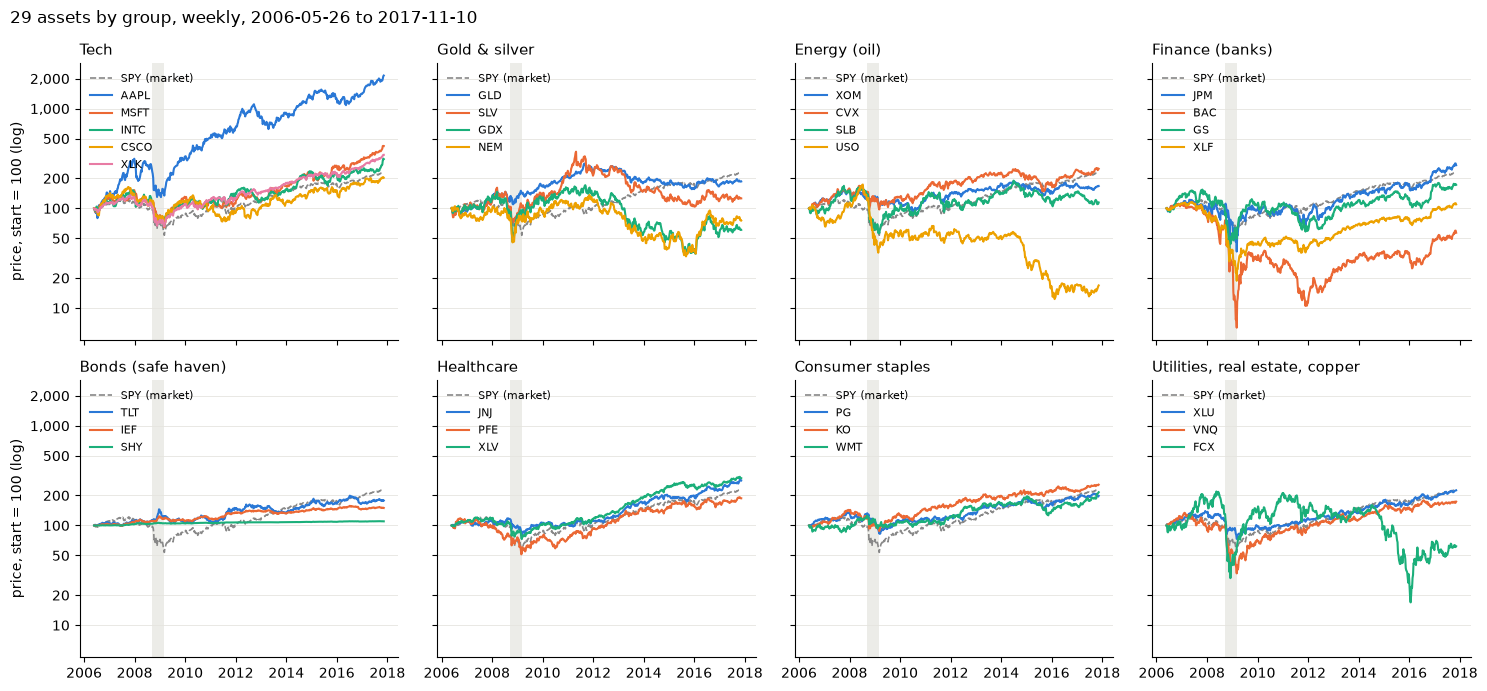

Text summary, average change per group in the 2008 crash window:
  Gold & silver                     4 assets   +12.0 %
  Bonds (safe haven)                3 assets    +5.4 %
  Consumer staples                  3 assets   -29.1 %
  Healthcare                        3 assets   -31.6 %
  Utilities                         1 assets   -36.5 %
  Tech                              5 assets   -40.5 %
  Energy (oil)                      4 assets   -43.1 %
  Market reference (not a qubit)    1 assets   -45.3 %
  Materials (copper)                1 assets   -54.1 %
  Real estate                       1 assets   -66.1 %
  Finance (banks)                   4 assets   -68.4 %


In [13]:
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
panels = [("Tech", ["Tech"]), ("Gold & silver", ["Gold & silver"]), ("Energy (oil)", ["Energy (oil)"]),
          ("Finance (banks)", ["Finance (banks)"]), ("Bonds (safe haven)", ["Bonds (safe haven)"]),
          ("Healthcare", ["Healthcare"]), ("Consumer staples", ["Consumer staples"]),
          ("Utilities, real estate, copper", ["Utilities", "Real estate", "Materials (copper)"])]
assert sum(len(assets[assets["group"].isin(g)]) for _, g in panels) == len(assets)
rebased_k = weekly / weekly.iloc[0] * 100

fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
for ax, (title, groups) in zip(axes.flat, panels):
    ax.axvspan(pd.Timestamp("2008-09-12"), pd.Timestamp("2009-03-06"), color="#e5e4df", alpha=0.7, linewidth=0)
    ax.plot(rebased_k.index, rebased_k[BENCHMARK], color="#888888", linewidth=1.2, linestyle="--", label="SPY (market)")
    members = [t for t in assets.index if assets.loc[t, "group"] in groups]
    for color, ticker in zip(palette, members):
        ax.plot(rebased_k.index, rebased_k[ticker], color=color, linewidth=1.5, label=ticker)
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(FixedLocator([10, 20, 50, 100, 200, 500, 1000, 2000]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_minor_locator(FixedLocator([]))
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("price, start = 100 (log)")
fig.suptitle(f"29 assets by group, weekly, {weekly.index[0].date()} to {weekly.index[-1].date()}", x=0.01, ha="left")
fig.tight_layout()
plt.show()

by_group = table.groupby("group", sort=False).agg(assets=("name", "size"), crash_avg=("2008 crash (%)", "mean"))
print("Text summary, average change per group in the 2008 crash window:")
for group, row in by_group.sort_values("crash_avg", ascending=False).iterrows():
    print(f"  {group:<32} {int(row['assets']):>2} assets  {row['crash_avg']:+6.1f} %")

### K.4 Which assets run at each size

Rule, fixed in advance and independent of performance: take **one asset from each group in turn** (groups and assets in the order of the K.2 table) until the size is reached. Every size keeps the groups balanced, and a smaller set is always contained in a larger one.

In [14]:
def select_assets(n, assets=assets):
    """First n tickers, taking one asset from each group in turn (K.2 order)."""
    if not 1 <= n <= len(assets):
        raise ValueError(f"n = {n}: choose between 1 and {len(assets)} assets")
    queues = {g: list(assets.index[assets["group"] == g]) for g in dict.fromkeys(assets["group"])}
    picked = []
    while len(picked) < n:
        for queue in queues.values():
            if queue and len(picked) < n:
                picked.append(queue.pop(0))
    return picked

selection = {n: select_assets(n) for n in RUN_SIZES}
for n, picked in selection.items():
    print(f"{n:>2} qubits, {assets.loc[picked, 'group'].nunique()} groups: {', '.join(picked)}")

membership = pd.DataFrame({f"{n} qubits": ["✓" if t in selection[n] else "" for t in assets.index]
                           for n in RUN_SIZES}, index=assets.index)
membership.insert(0, "group", assets["group"])
membership

12 qubits, 10 groups: AAPL, GLD, XOM, JPM, TLT, JNJ, PG, XLU, VNQ, FCX, MSFT, SLV
29 qubits, 10 groups: AAPL, GLD, XOM, JPM, TLT, JNJ, PG, XLU, VNQ, FCX, MSFT, SLV, CVX, BAC, IEF, PFE, KO, INTC, GDX, SLB, GS, SHY, XLV, WMT, CSCO, NEM, USO, XLF, XLK


,group,12 qubits,29 qubits
ticker,,,
AAPL,Tech,✓,✓
MSFT,Tech,✓,✓
INTC,Tech,,✓
CSCO,Tech,,✓
XLK,Tech,,✓
GLD,Gold & silver,✓,✓
SLV,Gold & silver,✓,✓
GDX,Gold & silver,,✓
NEM,Gold & silver,,✓
